# ScoNet: from .pkl to prediction

My notes on how ScoNet uses the .pkl files: loading, making a batch, the network, the loss, training and evaluation.
Same 3 subjects as in `raw_to_pkl`: positive 00000, neutral 01293, negative 00493.

I use the official `Scoliosis1K-sil-pkl` here, not my own .pkl files. In `raw_to_pkl` part 9 I found that the negative raw PNGs don't match the official negative pkl, and the paper results come from the official pkl.

Everything is written out in this notebook, nothing is imported from the `opengait` folder. The code follows:
- `opengait/data/transform.py`, `collate_fn.py`, `sampler.py` (loading and batches)
- `opengait/modeling/backbones/resnet.py`, `modules.py`, `models/sconet.py` (the network)
- `opengait/modeling/losses/triplet.py`, `ce.py` (the loss)
- `opengait/modeling/base_model.py`, `evaluation/evaluator.py` (training and evaluation)
- settings from `configs/sconet/sconet_scoliosis1k.yaml`

Important: with only 3 sequences the model can only memorise them. This notebook is for understanding the pipeline, the accuracy here means nothing for real screening.

Run the cells from top to bottom. Kernel: sconet (Python 3.10).

## 1 · Setup
New libraries compared to `raw_to_pkl`:
- `torch`: PyTorch, builds and trains the neural network on the GPU
- `torch.nn`: layers (convolution, batch norm, ...)
- `torch.nn.functional` (F): functions without weights (relu, cross entropy, normalize, ...)
- `sklearn.metrics`: accuracy, precision, recall, F1, confusion matrix

The settings come from `sconet_scoliosis1k.yaml`. Two things are different because I only have 3 sequences:
- batch: 3 subjects x 4 copies (the config uses 8 x 8)
- 300 iterations instead of 20000, the learning rate drops at the same relative points (50%, 70%, 90%)

`SEED` fixes the random numbers so every run gives the same result.

In [20]:
import os
import pickle
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

OPENGAIT = r"C:\Users\ASUS\.vscode\OpenGait"
PKL_ROOT = os.path.join(OPENGAIT, "datasets", "Scoliosis1K", "Scoliosis1K-sil-pkl")
OUT_ROOT = os.path.join(OPENGAIT, "self_learning", "pkl_to_sconet", "output")
FIG_DIR = os.path.join(OUT_ROOT, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

LABELS = {"negative": 0, "neutral": 1, "positive": 2}
LABEL_NAMES = ["negative", "neutral", "positive"]

FRAMES_TRAIN = 30
K = 4
TEST_FRAME_LIMIT = 720

LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4 #0,0005
TOTAL_ITER = 300
MILESTONES = [150, 210, 270]
GAMMA = 0.1
USE_FP16 = DEVICE == "cuda"

TRIPLET_MARGIN = 0.2
CE_SCALE = 16
LABEL_SMOOTH = 0.1


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("torch:", torch.__version__)

device: cuda NVIDIA GeForce RTX 3050 Laptop GPU
torch: 2.5.1+cu121


## 2 · Load the 3 .pkl files
Each item gets two numbers:
- `pid` (person id): 0, 1, 2. Used by the triplet loss to know which copies are the same person.
- `label` (class): negative 0, neutral 1, positive 2. Same mapping as in OpenGait `sconet.py`. Used by the cross entropy loss.

Each `seq` is the array from the .pkl: `(frames, 64, 64)`, uint8, values 0-255.

In [21]:
SUBJECTS = [("00000", "positive"), ("01293", "neutral"), ("00493", "negative")]
VIEW = "000_180"


def load_pkl(subject, cls, view=VIEW):
    path = os.path.join(PKL_ROOT, subject, cls, view, f"{view}.pkl")
    with open(path, "rb") as f:
        return pickle.load(f)


data = []
for pid, (subject, cls) in enumerate(SUBJECTS):
    seq = load_pkl(subject, cls)
    data.append({"subject": subject, "class": cls, "pid": pid, "label": LABELS[cls], "seq": seq})
    print(f"{cls:>8}: subject {subject} | pid {pid} | label {LABELS[cls]} | {seq.shape} {seq.dtype}")

positive: subject 00000 | pid 0 | label 2 | (300, 64, 64) uint8
 neutral: subject 01293 | pid 1 | label 1 | (300, 64, 64) uint8
negative: subject 00493 | pid 2 | label 0 | (300, 64, 64) uint8


### My result
- 3 sequences, each `(300, 64, 64)` uint8: 300 frames per child.
- positive gets pid 0 / label 2, neutral pid 1 / label 1, negative pid 2 / label 0.
- pid says which child it is (for the triplet loss), label says which class (for cross entropy). They are two different things that just happen to line up here because I have one child per class.

## 3 · Transform: 64 x 64 to 64 x 44, values 0-1
This is `BaseSilCuttingTransform` from OpenGait.
- `cut = int(64 // 64) * 10 = 10`, so 10 columns are removed on each side. Those columns are almost always black padding.
- divide by 255 so the values are between 0 and 1.

The red lines show which columns are kept.

before: (300, 64, 64) uint8 max 255
after : (300, 64, 44) float64 max 1.0


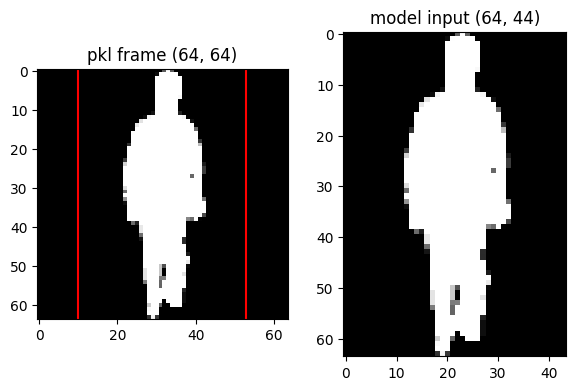

In [22]:
def sil_transform(seq):
    cut = int(seq.shape[-1] // 64) * 10
    return seq[..., cut:-cut] / 255.0


raw = data[0]["seq"]
x = sil_transform(raw)
print("before:", raw.shape, raw.dtype, "max", raw.max())
print("after :", x.shape, x.dtype, "max", x.max())

fig, ax = plt.subplots(1, 2, figsize=(6, 4))
ax[0].imshow(raw[150], cmap="gray")
ax[0].axvline(10, color="red")
ax[0].axvline(53, color="red")
ax[0].set_title(f"pkl frame {raw[150].shape}")
ax[1].imshow(x[150], cmap="gray", vmin=0, vmax=1)
ax[1].set_title(f"model input {x[150].shape}")
save_and_show(fig, "03_transform.png")

### My result
- `(300, 64, 64)` uint8, max 255 becomes `(300, 64, 44)` float, max 1.0.
- The red lines in the left picture are exactly the columns that stay. Only black is removed, the body is not touched.

## 4 · Which frames go into the model
Training (`fixed_unordered` in the config):
- pick 30 random frames from the 300, not in order
- every time the same sequence is used, a different set of 30 frames is picked, so the model sees many variations

Testing (`all_ordered`): all frames in order, at most 720 (to not run out of GPU memory).

The order does not matter for ScoNet, because later it takes the max over all frames (part 7).

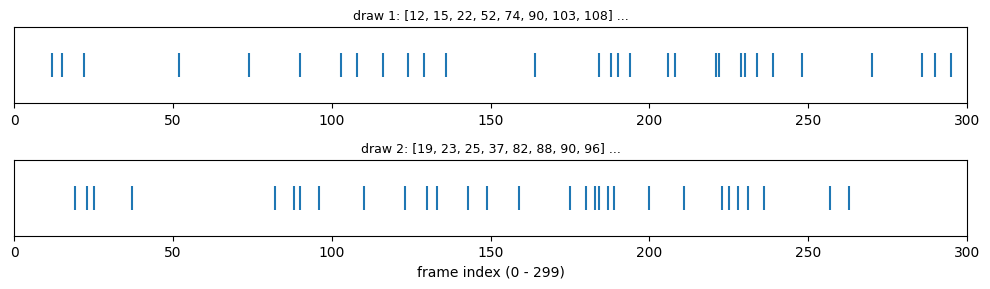

In [23]:
def sample_train_frames(seq, n=FRAMES_TRAIN):
    idx = np.random.choice(len(seq), n, replace=len(seq) < n)
    return seq[idx], idx


def all_test_frames(seq, limit=TEST_FRAME_LIMIT):
    return seq[:limit]


fig, ax = plt.subplots(2, 1, figsize=(10, 3))
for row in range(2):
    _, idx = sample_train_frames(data[0]["seq"])
    ax[row].scatter(idx, np.zeros_like(idx), marker="|", s=300)
    ax[row].set_xlim(0, len(data[0]["seq"]))
    ax[row].set_yticks([])
    ax[row].set_title(f"draw {row + 1}: {sorted(idx)[:8]} ...", fontsize=9)
ax[1].set_xlabel("frame index (0 - 299)")
save_and_show(fig, "04_frame_sampling.png")

## 5 · Making a training batch
This follows `TripletSampler`: pick P subjects, then K sequences of each subject.
- P = 3 here (all my subjects), K = 4, so 12 items in a batch.
- Each subject has only 1 sequence, so the same sequence is used 4 times, every time with different random frames.
- At the end the 12 items are shuffled (`batch_shuffle: true`).

Batch shape: `[12, 30, 64, 44]` = 12 items, 30 frames each, 64 x 44 pixels.

sils  : (12, 30, 64, 44) torch.float32
pids  : [0, 1, 2, 1, 0, 1, 1, 0, 2, 2, 0, 2]
labels: [2, 1, 0, 1, 2, 1, 1, 2, 0, 0, 2, 0]


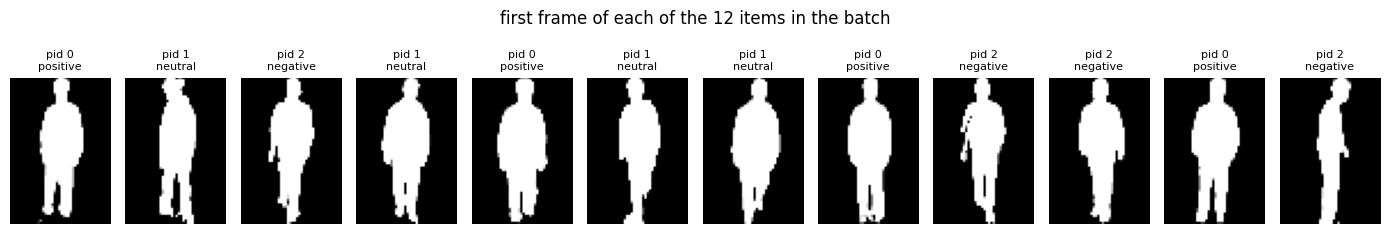

In [24]:
def make_train_batch(data, k=K):
    seqs, pids, labels = [], [], []
    for item in random.sample(data, len(data)):
        for _ in range(k):
            frames, _ = sample_train_frames(item["seq"])
            seqs.append(sil_transform(frames))
            pids.append(item["pid"])
            labels.append(item["label"])
    order = list(range(len(seqs)))
    random.shuffle(order)
    sils = torch.tensor(np.stack([seqs[i] for i in order]), dtype=torch.float32)
    pids = torch.tensor([pids[i] for i in order])
    labels = torch.tensor([labels[i] for i in order])
    return sils, pids, labels


sils, pids, labels = make_train_batch(data)
print("sils  :", tuple(sils.shape), sils.dtype)
print("pids  :", pids.tolist())
print("labels:", labels.tolist())

fig, ax = plt.subplots(1, len(sils), figsize=(14, 2.6))
for i in range(len(sils)):
    ax[i].imshow(sils[i, 0], cmap="gray", vmin=0, vmax=1)
    ax[i].set_title(f"pid {pids[i].item()}\n{LABEL_NAMES[labels[i]]}", fontsize=8)
    ax[i].axis("off")
fig.suptitle("first frame of each of the 12 items in the batch")
save_and_show(fig, "05_batch.png")

### My result
- Batch shape `(12, 30, 64, 44)`: 12 items, 30 frames each.
- pids `[0, 1, 2, 1, 0, 1, 1, 0, 2, 2, 0, 2]`: every child shows up exactly 4 times, shuffled.
- The 4 copies of one child are the same video with different random frames. That is what gives the triplet loss "positive" pairs even though every child has only one video.

## 6 · The backbone: ResNet9
The backbone looks at every frame on its own and turns it into feature maps.

`BasicBlock` (the residual block):
- conv 3x3, batch norm, relu, conv 3x3, batch norm
- then add the input back (`out + identity`) and relu. This "skip connection" makes deep networks easier to train.
- if the size or channel count changes, the input goes through a 1x1 conv first (`downsample`) so it can be added.

`ResNet9` in ScoNet:
- first conv 3x3, 1 to 64 channels, no max pool
- 4 blocks: 64, 128, 256, 512 channels, strides 1, 2, 2, 1
- stride 2 halves the height and width, so 64 x 44 becomes 16 x 11 at the end

All frames of all items are put in one big batch (`n * s` images), that is what `SetBlockWrapper` does in OpenGait.

In [25]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class ResNet9(nn.Module):
    def __init__(self, channels=(64, 128, 256, 512), strides=(1, 2, 2, 1)):
        super().__init__()
        self.conv1 = nn.Conv2d(1, channels[0], 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels[0])
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = BasicBlock(channels[0], channels[0], strides[0])
        self.layer2 = BasicBlock(channels[0], channels[1], strides[1])
        self.layer3 = BasicBlock(channels[1], channels[2], strides[2])
        self.layer4 = BasicBlock(channels[2], channels[3], strides[3])

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        return self.layer4(x)

### Experiment: shape after every layer
I send one item (30 frames) through the backbone step by step.
The weights are still random here, so the feature maps don't mean anything yet. I look at them again after training (part 13).

  input: (30, 1, 64, 44)
  conv1: (30, 64, 64, 44)
 layer1: (30, 64, 64, 44)
 layer2: (30, 128, 32, 22)
 layer3: (30, 256, 16, 11)
 layer4: (30, 512, 16, 11)


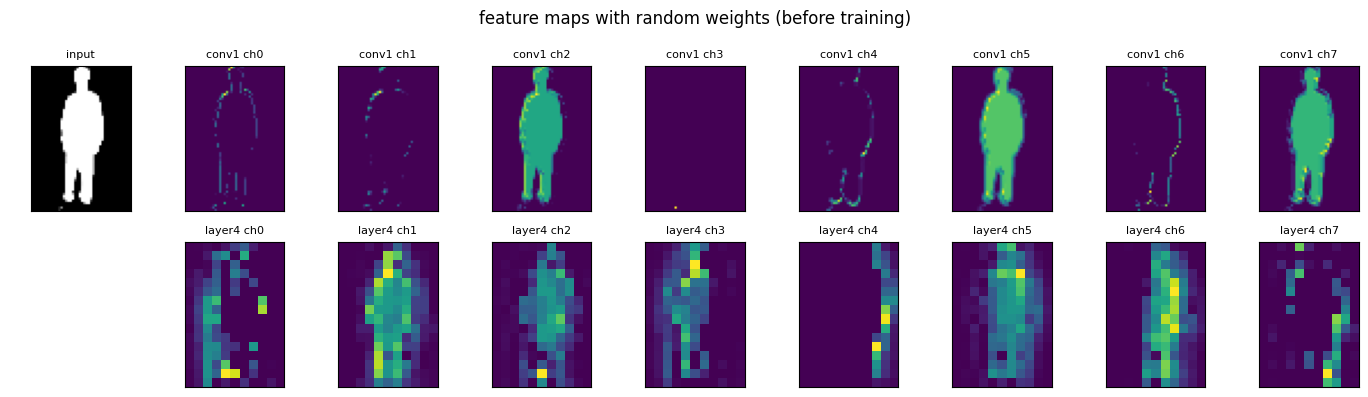

In [26]:
def trace_backbone(backbone, frames):
    shapes = {}
    with torch.no_grad():
        x = frames.unsqueeze(1)
        shapes["input"] = x
        x = backbone.relu(backbone.bn1(backbone.conv1(x)))
        shapes["conv1"] = x
        for name in ["layer1", "layer2", "layer3", "layer4"]:
            x = getattr(backbone, name)(x)
            shapes[name] = x
    return shapes


def show_feature_maps(feats, frame_i, name, title):
    fig, ax = plt.subplots(2, 9, figsize=(14, 4))
    ax[0, 0].imshow(feats["input"][frame_i, 0].cpu(), cmap="gray")
    ax[0, 0].set_title("input", fontsize=8)
    ax[1, 0].axis("off")
    for j in range(8):
        ax[0, j + 1].imshow(feats["conv1"][frame_i, j].float().cpu(), cmap="viridis")
        ax[0, j + 1].set_title(f"conv1 ch{j}", fontsize=8)
        ax[1, j + 1].imshow(feats["layer4"][frame_i, j].float().cpu(), cmap="viridis")
        ax[1, j + 1].set_title(f"layer4 ch{j}", fontsize=8)
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(title)
    save_and_show(fig, name)


backbone = ResNet9().eval()
demo_frames = sils[0].clone()
feats = trace_backbone(backbone, demo_frames)
for k, v in feats.items():
    print(f"{k:>7}: {tuple(v.shape)}")
show_feature_maps(feats, 0, "06_features_random.png", "feature maps with random weights (before training)")

### My result
```
input  (30, 1, 64, 44)
conv1  (30, 64, 64, 44)
layer1 (30, 64, 64, 44)
layer2 (30, 128, 32, 22)   stride 2, half size
layer3 (30, 256, 16, 11)   stride 2, half again
layer4 (30, 512, 16, 11)
```
- The size goes 64 x 44 to 16 x 11 while the channels go 1 to 512: less "where", more "what".
- With random weights the conv1 maps are a random mix: some light up the body, some only bits of the edge. The layer4 maps are noisy blobs.
- This picture comes from a separate untrained backbone, not the exact starting weights of the model I train later. Both are random, so it still shows what "untrained" looks like.

## 7 · Temporal pooling: max over frames
After the backbone every frame has its own feature map `[512, 16, 11]`.
ScoNet keeps, for every position, the highest value over all frames (`torch.max` over the frame axis).
- the result does not depend on how many frames there are or in which order they are
- this is why a sequence is treated as a set of frames, not as a video

`[n, s, 512, 16, 11]` becomes `[n, 512, 16, 11]`.

In [27]:
def temporal_max(x, n, s):
    x = x.reshape(n, s, *x.shape[1:])
    return x.max(dim=1)[0]


with torch.no_grad():
    per_frame = feats["layer4"]
    pooled = temporal_max(per_frame, 1, per_frame.shape[0])
print("per frame:", tuple(per_frame.shape), "-> pooled:", tuple(pooled.shape))

with torch.no_grad():
    shuffled = per_frame[torch.randperm(per_frame.shape[0])]
    print("same result with shuffled frames:", torch.equal(pooled, temporal_max(shuffled, 1, shuffled.shape[0])))

per frame: (30, 512, 16, 11) -> pooled: (1, 512, 16, 11)
same result with shuffled frames: True


### My result
- `(30, 512, 16, 11)` becomes `(1, 512, 16, 11)`: 30 frames are squeezed into one feature map.
- "same result with shuffled frames: True". So ScoNet really does not care about frame order. It sees the walk as a set of poses, not as a movie.

## 8 · Horizontal pooling: 16 body strips
`HorizontalPoolingPyramid` with `bin_num: [16]`.
- the 16 rows of the feature map become 16 strips, one per body height (head, shoulders, trunk, hips, legs ...)
- for each strip: mean + max over the 11 columns
- `[n, 512, 16, 11]` becomes `[n, 512, 16]`: 512 numbers for each of the 16 strips

Every strip is about 4 rows of the original 64 row image (64 / 16 = 4). The figure shows the strips on top of a silhouette.
For scoliosis this makes sense: uneven shoulders or a tilted trunk show up at specific heights.

pooled: (1, 512, 16, 11) -> strips: (1, 512, 16)


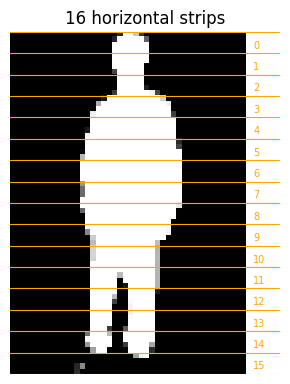

In [ ]:
def horizontal_pooling(x, bins=16):
    n, c = x.shape[:2]
    z = x.view(n, c, bins, -1)
    return z.mean(-1) + z.max(-1)[0]

strips = horizontal_pooling(pooled)
print("pooled:", tuple(pooled.shape), "-> strips:", tuple(strips.shape))

fig, ax = plt.subplots(figsize=(3, 4.5))
ax.imshow(sils[0, 0], cmap="gray", vmin=0, vmax=1)
for b in range(17):
    ax.axhline(b * 4 - 0.5, color="orange", lw=0.8)
for b in range(16):
    ax.text(45, b * 4 + 2, str(b), color="orange", fontsize=7, va="center")
ax.set_xlim(-0.5, 50)
ax.set_title("16 horizontal strips")
ax.axis("off")
save_and_show(fig, "08_strips.png")

### My result
- `(1, 512, 16, 11)` becomes `(1, 512, 16)`: 512 numbers for each of the 16 body strips.
- Each strip covers 4 rows of the 64 row silhouette, from strip 0 at the head to strip 15 at the feet.

## 9 · Separate FC and BNNeck: from strips to class scores
`SeparateFCs`: every strip has its own linear layer, 512 to 256. So strip 3 (shoulders) and strip 12 (knees) learn different things.
Output `[n, 256, 16]`: this is the **embedding** used by the triplet loss.

`SeparateBNNecks`:
- batch norm over all 256 x 16 numbers
- `F.normalize`: every strip vector gets length 1
- multiply with the normalised class weights: this is the cosine similarity between the strip and each class, between -1 and 1
- output `[n, 3, 16]`: the **logits**, a score for each class in each strip, used by the cross entropy loss

`matmul` does all 16 strips at once: `[16, n, 512] x [16, 512, 256]` = `[16, n, 256]`.

In [29]:
class SeparateFCs(nn.Module):
    def __init__(self, parts, in_ch, out_ch):
        super().__init__()
        self.fc_bin = nn.Parameter(nn.init.xavier_uniform_(torch.zeros(parts, in_ch, out_ch)))

    def forward(self, x):
        x = x.permute(2, 0, 1)
        out = x.matmul(self.fc_bin)
        return out.permute(1, 2, 0).contiguous()


class SeparateBNNecks(nn.Module):
    def __init__(self, parts, in_ch, class_num):
        super().__init__()
        self.fc_bin = nn.Parameter(nn.init.xavier_uniform_(torch.zeros(parts, in_ch, class_num)))
        self.bn1d = nn.BatchNorm1d(in_ch * parts)

    def forward(self, x):
        n, c, p = x.shape
        x = self.bn1d(x.reshape(n, -1)).reshape(n, c, p)
        feature = F.normalize(x.permute(2, 0, 1), dim=-1)
        logits = feature.matmul(F.normalize(self.fc_bin, dim=1))
        return feature.permute(1, 2, 0).contiguous(), logits.permute(1, 2, 0).contiguous()

## 10 · The full ScoNet
Putting parts 6 to 9 together:

`[n, s, 64, 44]` -> ResNet9 on every frame -> max over frames -> 16 strips -> SeparateFCs (embedding) -> BNNeck (logits)

`init_parameters` is the same as `BaseModel.init_parameters` in OpenGait: xavier for conv and linear weights, batch norm weights around 1.
About 7 million numbers (parameters) are learned.

In [30]:
class ScoNet(nn.Module):
    def __init__(self, num_classes=3, parts=16, embed_dim=256):
        super().__init__()
        self.parts = parts
        self.backbone = ResNet9()
        self.fcs = SeparateFCs(parts, 512, embed_dim)
        self.bnnecks = SeparateBNNecks(parts, embed_dim, num_classes)
        self.init_parameters()

    def init_parameters(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.normal_(m.weight, 1.0, 0.02)
                nn.init.zeros_(m.bias)

    def forward(self, sils):
        n, s, h, w = sils.shape
        x = self.backbone(sils.reshape(n * s, 1, h, w))
        x = temporal_max(x, n, s)
        feat = horizontal_pooling(x, self.parts)
        embed = self.fcs(feat)
        _, logits = self.bnnecks(embed)
        return embed, logits


model = ScoNet().to(DEVICE)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} million")

with torch.no_grad():
    embed, logits = model.eval()(sils.to(DEVICE))
print("embedding:", tuple(embed.shape), " logits:", tuple(logits.shape))

parameters: 7.01 million
embedding: (12, 256, 16)  logits: (12, 3, 16)


### My result
- 7.01 million parameters.
- A batch of 12 gives an embedding `(12, 256, 16)` and logits `(12, 3, 16)`: 3 class scores for each of the 16 strips.

## 11 · The loss: triplet + cross entropy
`total loss = 1.0 x triplet + 1.0 x cross entropy` (from `loss_cfg` in the config). Using both is the "multi-task" part of ScoNet-MT.

**Triplet loss** (margin 0.2), on the embedding, using `pid`:
- for every anchor a, every positive p (same person) and every negative n (other person): `max(0, d(a,p) - d(a,n) + 0.2)`
- so the copies of the same person must be closer to each other than to anyone else, by at least 0.2
- the average is taken only over the triplets that are not 0 yet (`AvgNonZeroReducer`), so easy triplets don't hide the hard ones
- done for every strip separately, then averaged
- the distance is euclidean: `sqrt(|x|^2 + |y|^2 - 2 x.y)`

**Cross entropy** (scale 16, label smoothing 0.1), on the logits, using `label`:
- logits are cosine values in -1..1, times 16 makes the softmax sharp enough to learn
- label smoothing 0.1: the target is not 100% the right class, a bit is spread to the other classes, so the model doesn't get overconfident
- done for every strip with the same label

The figure shows the distance between the 12 batch items for strip 0, before training. Same pid should become dark (close) after training.

triplet 0.1949 (non-zero triplets per strip 384) | ce 1.4683 | acc 0.333


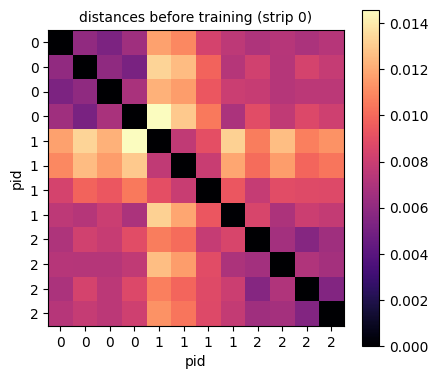

In [31]:
def triplet_loss(embed, pids, margin=TRIPLET_MARGIN):
    x = embed.permute(2, 0, 1).float()
    x2 = (x ** 2).sum(-1)
    dist = torch.sqrt(F.relu(x2.unsqueeze(2) + x2.unsqueeze(1) - 2 * x.matmul(x.transpose(1, 2))))
    same = pids.unsqueeze(1) == pids.unsqueeze(0)
    p, n, _ = dist.shape
    ap = dist[:, same].view(p, n, -1, 1)
    an = dist[:, ~same].view(p, n, 1, -1)
    loss = F.relu(ap - an + margin).view(p, -1)
    num = (loss != 0).sum(-1).float()
    avg = loss.sum(-1) / (num + 1e-9)
    avg[num == 0] = 0
    return avg.mean(), num.mean(), dist


def ce_loss(logits, labels, scale=CE_SCALE, eps=LABEL_SMOOTH):
    n, c, p = logits.shape
    loss = F.cross_entropy(logits.float() * scale, labels.unsqueeze(1).repeat(1, p), label_smoothing=eps)
    acc = (logits.argmax(1) == labels.unsqueeze(1)).float().mean()
    return loss, acc


def show_distances(dist, pids, name, title):
    order = torch.argsort(pids.cpu())
    d = dist[0].detach().float().cpu()[order][:, order]
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(d, cmap="magma")
    ticks = [str(v) for v in pids.cpu()[order].tolist()]
    ax.set_xticks(range(len(ticks)), ticks)
    ax.set_yticks(range(len(ticks)), ticks)
    ax.set_xlabel("pid")
    ax.set_ylabel("pid")
    ax.set_title(title, fontsize=10)
    fig.colorbar(im)
    save_and_show(fig, name)


pids_d, labels_d = pids.to(DEVICE), labels.to(DEVICE)
with torch.no_grad():
    l_tri, n_tri, dist = triplet_loss(embed, pids_d)
    l_ce, acc = ce_loss(logits, labels_d)
print(f"triplet {l_tri.item():.4f} (non-zero triplets per strip {n_tri.item():.0f}) | ce {l_ce.item():.4f} | acc {acc.item():.3f}")
show_distances(dist, pids, "11_distances_before.png", "distances before training (strip 0)")

### My result (before training)
`triplet 0.1949 | non-zero triplets 384 | ce 1.4683 | acc 0.333`
- acc 0.333 is 1 out of 3, the same as guessing.
- 384 non-zero triplets is all of them: 12 anchors x 4 positives x 8 negatives = 384. Every triplet breaks the rule.
- The distance picture explains why: all distances are between 0.000 and 0.014, far under the 0.2 margin. Before training every child looks the same to the model.

## 12 · Optimizer and learning rate
- **SGD** with momentum 0.9: every step moves the weights a bit against the gradient, momentum keeps some of the previous direction so it is smoother
- **weight decay** 5e-4: pulls weights a little to 0 every step, against overfitting
- **MultiStepLR**: start with lr 0.1, multiply by 0.1 at iteration 150, 210 and 270. Big steps first, then small steps to fine tune. It counts iterations, not epochs.
- **fp16 (mixed precision)** with `GradScaler`: faster and less GPU memory. The loss is scaled up so small gradients don't become 0 in fp16. If the gradients overflow, that step is skipped and the scale gets smaller.

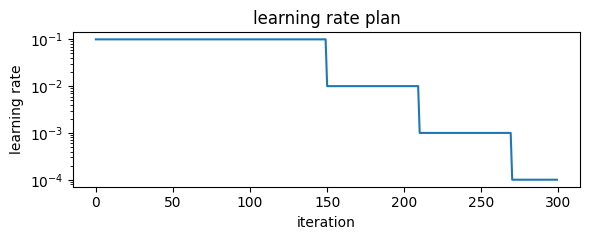

In [32]:
model = ScoNet().to(DEVICE)
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=MILESTONES, gamma=GAMMA)
scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)

lr_plan = [LR * GAMMA ** sum(it >= m for m in MILESTONES) for it in range(TOTAL_ITER)]
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(lr_plan)
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("learning rate")
ax.set_title("learning rate plan")
save_and_show(fig, "12_lr.png")

### My result
lr is 0.1 until iteration 150, then 0.01, 0.001 from 210, and 0.0001 from 270. On the log scale it looks like stairs going down.

## 13 · Training
One iteration:
1. make a new batch (new random frames every time)
2. forward: model gives embedding and logits
3. loss = triplet + cross entropy
4. `zero_grad`, then `backward` computes the gradients, `step` updates the weights
5. `scheduler.step()` moves the learning rate plan one iteration

`model.train()` is important: batch norm uses the statistics of the current batch and keeps updating its running averages.

In [33]:
history = {"loss": [], "triplet": [], "ce": [], "acc": [], "lr": []}
model.train()
it = 0
t0 = time.time()
while it < TOTAL_ITER:
    sils, pids, labels = make_train_batch(data)
    sils, pids, labels = sils.to(DEVICE), pids.to(DEVICE), labels.to(DEVICE)

    with torch.autocast(device_type=DEVICE, enabled=USE_FP16):
        embed, logits = model(sils)
    l_tri, n_tri, _ = triplet_loss(embed, pids)
    l_ce, acc = ce_loss(logits, labels)
    loss = l_tri + l_ce

    optimizer.zero_grad()
    scaler.scale(loss).backward()
    scale_before = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    if scale_before != scaler.get_scale():
        continue
    it += 1
    scheduler.step()

    history["loss"].append(loss.item())
    history["triplet"].append(l_tri.item())
    history["ce"].append(l_ce.item())
    history["acc"].append(acc.item())
    history["lr"].append(optimizer.param_groups[0]["lr"])
    if it % 25 == 0:
        print(f"iter {it:4d} | loss {loss.item():.4f} | triplet {l_tri.item():.4f} | ce {l_ce.item():.4f} "
              f"| acc {acc.item():.3f} | lr {history['lr'][-1]:.4g} | {time.time() - t0:.0f}s")

iter   25 | loss 0.6955 | triplet 0.2557 | ce 0.4398 | acc 1.000 | lr 0.1 | 13s
iter   50 | loss 0.3089 | triplet 0.0000 | ce 0.3089 | acc 1.000 | lr 0.1 | 23s
iter   75 | loss 0.3138 | triplet 0.0058 | ce 0.3080 | acc 1.000 | lr 0.1 | 33s
iter  100 | loss 0.3247 | triplet 0.0237 | ce 0.3010 | acc 1.000 | lr 0.1 | 43s
iter  125 | loss 0.3018 | triplet 0.0000 | ce 0.3018 | acc 1.000 | lr 0.1 | 55s
iter  150 | loss 0.3147 | triplet 0.0166 | ce 0.2981 | acc 1.000 | lr 0.01 | 68s
iter  175 | loss 0.2966 | triplet 0.0000 | ce 0.2966 | acc 1.000 | lr 0.01 | 85s
iter  200 | loss 0.3992 | triplet 0.1016 | ce 0.2976 | acc 1.000 | lr 0.01 | 107s
iter  225 | loss 0.2963 | triplet 0.0000 | ce 0.2963 | acc 1.000 | lr 0.001 | 119s
iter  250 | loss 0.3087 | triplet 0.0112 | ce 0.2975 | acc 1.000 | lr 0.001 | 131s
iter  275 | loss 0.2965 | triplet 0.0000 | ce 0.2965 | acc 1.000 | lr 0.0001 | 143s
iter  300 | loss 0.2965 | triplet 0.0000 | ce 0.2965 | acc 1.000 | lr 0.0001 | 155s


### My result
```
iter  25 | loss 0.6955 | triplet 0.2557 | ce 0.4398 | acc 1.000
iter  50 | loss 0.3089 | triplet 0.0000 | ce 0.3089 | acc 1.000
iter 300 | loss 0.2965 | triplet 0.0000 | ce 0.2965 | acc 1.000
```
- Training accuracy is 100% already at iteration 25. Telling 3 children apart is very easy.
- 300 iterations took about 2 minutes on my RTX 3050.

### Training curves
- triplet goes to 0 when every person's copies are closer together than to the other people by the margin
- cross entropy does not go to 0 because of label smoothing, it stops at a small value
- accuracy here is per strip on the training batch

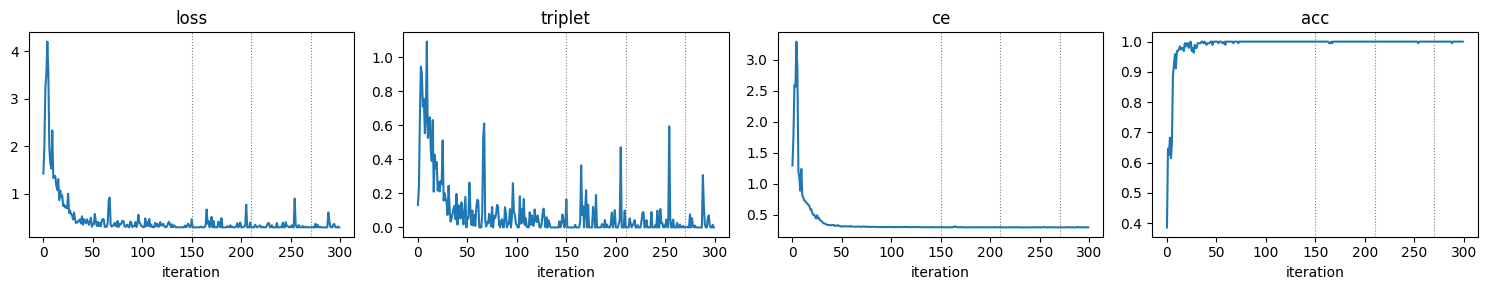

In [34]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, key in zip(ax, ["loss", "triplet", "ce", "acc"]):
    a.plot(history[key])
    for m in MILESTONES:
        a.axvline(m, color="gray", ls=":", lw=0.8)
    a.set_title(key)
    a.set_xlabel("iteration")
save_and_show(fig, "13_training_curves.png")

### My result
- The loss goes up first (to about 4) in the first few iterations. lr 0.1 makes big jumpy steps at the start, then it settles.
- Cross entropy stops at 0.2965, not 0. That is label smoothing: the target is 93.3% for the right class and 3.3% for each other class, and the lowest possible loss for that target is about 0.29. So it reached the floor.
- Triplet keeps jumping (spikes up to 0.6) but goes back to 0. Every batch has new random frames and some are harder, the model fixes them again.
- The lr drops at 150, 210, 270 change almost nothing here, because the model was already done at about iteration 50. With the full dataset they matter more.

### After training: feature maps and distances again
Same frame as in part 6, now with the trained backbone. And the distance matrix of a new batch: the same pid should be close now.

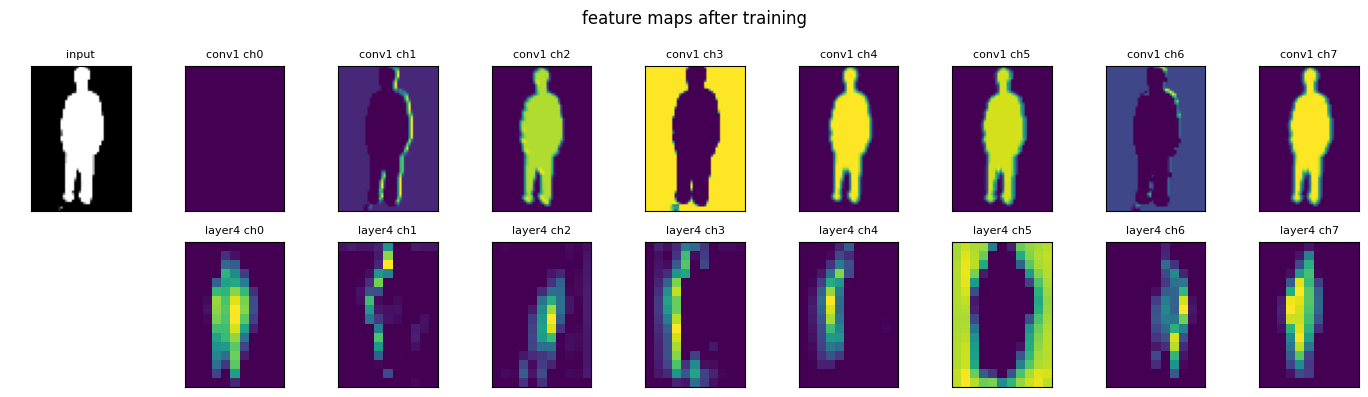

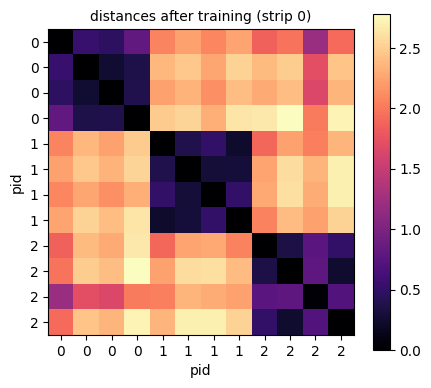

In [35]:
model.eval()
feats_trained = trace_backbone(model.backbone, demo_frames.to(DEVICE))
show_feature_maps(feats_trained, 0, "13_features_trained.png", "feature maps after training")

sils_b, pids_b, _ = make_train_batch(data)
with torch.no_grad():
    embed_b, _ = model(sils_b.to(DEVICE))
    _, _, dist_b = triplet_loss(embed_b, pids_b.to(DEVICE))
show_distances(dist_b, pids_b, "13_distances_after.png", "distances after training (strip 0)")

### My result (after training)
Feature maps, same frame as in part 6:
- conv1 channels now have one clear job each: ch2, ch4, ch5, ch7 fill the body, ch3 is the background, ch1 and ch6 only the edge on one side of the body. ch0 is off for this frame.
- layer4 channels look at specific parts: ch0 and ch7 the middle of the trunk, ch3 and ch4 the left side, ch6 the right side, ch5 the area around the body (the outline from outside).

Distances, strip 0:
- now between 0 and about 2.7 (before training it was 0 to 0.014)
- dark squares on the diagonal: the 4 copies of the same child are close together (under 0.5) and far from the other children (about 2 to 2.7). That is exactly what the triplet loss wants.

## 14 · Evaluation
Like `evaluate_scoliosis` in OpenGait:
- `model.eval()`: batch norm uses the running averages from training, not the test batch
- `torch.no_grad()`: no gradients needed, saves memory
- every sequence goes in with all its frames, in order, one at a time
- prediction = `argmax` of the logits averaged over the 16 strips
- metrics: accuracy, and macro precision / recall / F1 (each class computed alone, then averaged, so a small class counts as much as a big one)

The probability column is softmax of (mean logits x 16), only to make the scores easier to read. The prediction itself is just the argmax.

Here I test on the same 3 sequences I trained on, so it should be 100%. That only shows the model memorised them.

subject 00000 | true positive | predicted positive | negative 0.04  neutral 0.10  positive 0.85
subject 01293 | true  neutral | predicted  neutral | negative 0.05  neutral 0.92  positive 0.03
subject 00493 | true negative | predicted negative | negative 0.85  neutral 0.12  positive 0.03

accuracy  100.00%
precision 100.00% (macro)
recall    100.00% (macro)
f1        100.00% (macro)


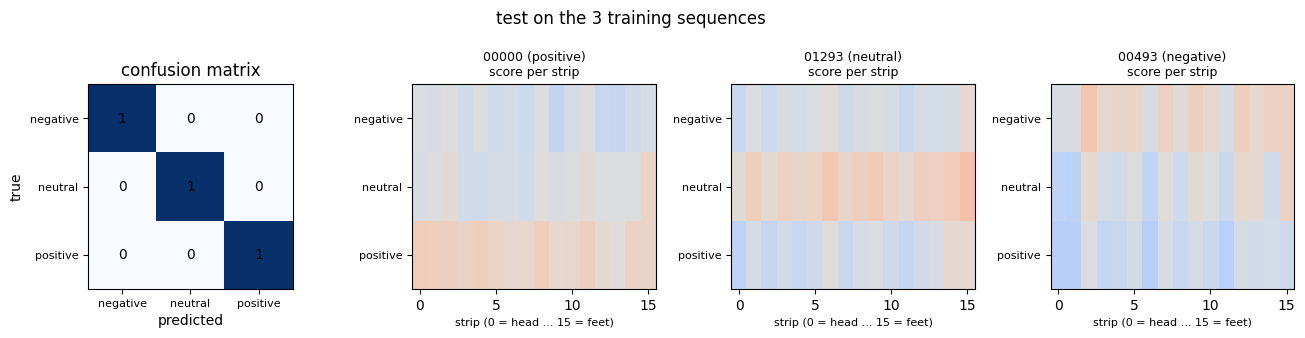

In [36]:
def predict(model, seq):
    x = torch.tensor(sil_transform(all_test_frames(seq)), dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad(), torch.autocast(device_type=DEVICE, enabled=USE_FP16):
        _, logits = model(x)
    mean_logits = logits.float().mean(-1)[0]
    prob = F.softmax(mean_logits * CE_SCALE, dim=-1).cpu().numpy()
    return mean_logits.argmax().item(), prob, logits.float()[0].cpu().numpy()


def evaluate(model, items, title, name):
    model.eval()
    y_true, y_pred, strip_logits = [], [], []
    for item in items:
        pred, prob, per_strip = predict(model, item["seq"])
        y_true.append(item["label"])
        y_pred.append(pred)
        strip_logits.append(per_strip)
        probs = "  ".join(f"{LABEL_NAMES[c]} {prob[c]:.2f}" for c in range(3))
        print(f"subject {item['subject']} | true {item['class']:>8} | predicted {LABEL_NAMES[pred]:>8} | {probs}")

    print(f"\naccuracy  {accuracy_score(y_true, y_pred) * 100:.2f}%")
    print(f"precision {precision_score(y_true, y_pred, average='macro', zero_division=0) * 100:.2f}% (macro)")
    print(f"recall    {recall_score(y_true, y_pred, average='macro', zero_division=0) * 100:.2f}% (macro)")
    print(f"f1        {f1_score(y_true, y_pred, average='macro', zero_division=0) * 100:.2f}% (macro)")

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    fig, ax = plt.subplots(1, 1 + len(items), figsize=(4 + 3.2 * len(items), 3.4),
                           gridspec_kw={"width_ratios": [1.2] + [1] * len(items)})
    ax[0].imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax[0].text(j, i, cm[i, j], ha="center", va="center")
    ax[0].set_xticks(range(3), LABEL_NAMES, fontsize=8)
    ax[0].set_yticks(range(3), LABEL_NAMES, fontsize=8)
    ax[0].set_xlabel("predicted")
    ax[0].set_ylabel("true")
    ax[0].set_title("confusion matrix")
    for a, item, per_strip in zip(ax[1:], items, strip_logits):
        a.imshow(per_strip, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
        a.set_yticks(range(3), LABEL_NAMES, fontsize=8)
        a.set_xlabel("strip (0 = head ... 15 = feet)", fontsize=8)
        a.set_title(f"{item['subject']} ({item['class']})\nscore per strip", fontsize=9)
    fig.suptitle(title)
    save_and_show(fig, name)


evaluate(model, data, "test on the 3 training sequences", "14_eval_train.png")

### My result (the 3 training children)
| child | true | predicted | confidence |
|---|---|---|---|
| 00000 | positive | positive | 0.85 |
| 01293 | neutral | neutral | 0.92 |
| 00493 | negative | negative | 0.85 |

- 100% on every metric. The model has seen these videos 300 times, so this is memorising, not diagnosing.
- In the strip pictures the right class is reddish over almost all 16 strips, from head to feet. The model does not look at one body region, it recognises the whole body of each child. With 3 children the easiest solution is "which of my 3 people is this", not "is the spine curved".

### Experiment: 3 children the model has never seen
One more subject per class from the official pkl (positive 00001, neutral 01294, negative 00494), not used in training.
With only 3 training sequences I expect the predictions to be close to guessing. This is why ScoNet needs the full training split (hundreds of children), not 3.

subject 00001 | true positive | predicted positive | negative 0.32  neutral 0.25  positive 0.43
subject 01294 | true  neutral | predicted  neutral | negative 0.06  neutral 0.90  positive 0.04
subject 00494 | true negative | predicted  neutral | negative 0.33  neutral 0.55  positive 0.12

accuracy  66.67%
precision 50.00% (macro)
recall    66.67% (macro)
f1        55.56% (macro)


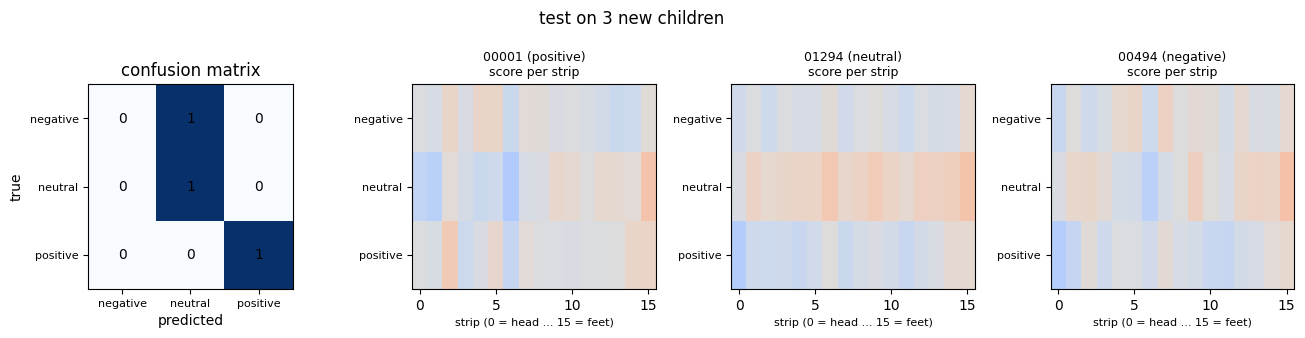

In [37]:
NEW_SUBJECTS = [("00001", "positive"), ("01294", "neutral"), ("00494", "negative")]
new_data = [{"subject": s, "class": c, "label": LABELS[c], "seq": load_pkl(s, c)} for s, c in NEW_SUBJECTS]
evaluate(model, new_data, "test on 3 new children", "14_eval_new.png")

### My result (3 new children)
| child | true | predicted | confidence |
|---|---|---|---|
| 00001 | positive | positive | 0.43 (weak, the others are 0.32 and 0.25) |
| 01294 | neutral | neutral | 0.90 |
| 00494 | negative | neutral (wrong) | 0.55 |

accuracy 66.67%, macro precision 50%, macro recall 66.67%, macro F1 55.56%.

How the macro numbers come out:
| class | precision | recall | F1 |
|---|---|---|---|
| negative | 0 (never predicted) | 0 / 1 = 0 | 0 |
| neutral | 1 right out of 2 predicted = 0.5 | 1 / 1 = 1 | 0.667 |
| positive | 1 / 1 = 1 | 1 / 1 = 1 | 1 |
| average | 50% | 66.7% | 55.6% |

- Accuracy says 2 out of 3, but macro F1 is lower because the negative class was missed completely. That is why the paper reports macro F1.
- 2 out of 3 is not proof of anything. With only 3 test children it can easily be luck, and the positive one was barely confident.
- The model mostly learned what my 3 training children look like. To learn scoliosis it needs the full training split (744 children in the 1:1:8 split), not 3.

## 15 · Save the model
`state_dict` holds all the learned weights. It can be loaded later with `model.load_state_dict(torch.load(path))`.

In [38]:
ckpt_path = os.path.join(OUT_ROOT, "sconet_3samples.pt")
torch.save(model.state_dict(), ckpt_path)
print("saved", ckpt_path)

saved C:\Users\ASUS\.vscode\OpenGait\self_learning\pkl_to_sconet\output\sconet_3samples.pt


## Summary
.pkl `(300, 64, 64)` -> cut + divide by 255 `(300, 64, 44)` -> 30 random frames, 4 copies per person `[12, 30, 64, 44]`
-> ResNet9 per frame `[360, 512, 16, 11]` -> max over frames `[12, 512, 16, 11]` -> 16 strips `[12, 512, 16]`
-> SeparateFCs embedding `[12, 256, 16]` (triplet loss with pid) -> BNNeck logits `[12, 3, 16]` (cross entropy with class)
-> SGD + MultiStepLR -> test: all frames, mean of the 16 strips, argmax -> accuracy, macro precision / recall / F1